# [파이썬 데이터 전처리 & 시각화] 과제  
## 제출 일정: 2026-11-23 ~ 2026-11-30까지

---

## 진행 안내

<u>**진행 방식**</u>

1. 제공된 `hotel_bookings.csv`를 활용합니다.
2. 원본 데이터는 `booking_raw`에 저장하고 수정하지 않습니다. 정제 결과는 `booking_clean`에 저장합니다.
3. Pandas, Matplotlib, Seaborn을 사용할 수 있습니다.
4. 문제 1~7을 순서대로 수행하고, 각 문제의 코드와 실행 결과를 함께 남깁니다.
5. 처리 근거와 해석은 코드 주석 또는 마크다운 셀에 작성합니다.
6. 모든 셀을 위에서부터 순서대로 실행할 수 있도록 작성합니다.

<u>**제출 시 유의사항**</u>

- 문제별 코드·실행 결과·설명을 포함한 주피터 노트북(`.ipynb`)을 Github에 올려 링크로 제출합니다.
- 결측값을 모두 0으로 바꾸지 않고, 명확한 오류와 단순히 큰 값을 구분합니다. 오류 값과 관련 없는 정상 데이터는 변형하지 않습니다.
- `daily_rate`는 보존합니다. 이상치 처리 결과는 `daily_rate_processed`에 저장하고, `estimated_room_amount`는 `daily_rate`로 계산합니다.
- 미취소 예약은 기준 시점에 취소되지 않은 예약이며, 최종 투숙 완료 예약이 아닙니다. 관측 취소율을 최종 취소율이나 인과관계로 단정하지 않습니다.
- 제출 전 런타임을 다시 시작하고 전체 셀이 순서대로 실행되는지 확인합니다.

<aside>
Github 레포지토리는 항상 public으로 전환하여 첨부합니다.
레포지토리 링크로 잘 첨부되었는지 꼭 확인 후 제출합니다!

</aside>

<u>**수강생 과제 수행 TIP!**</u>

1. 전체 예약 현황과 데이터 품질을 확인한 뒤, 정제 → 이상치 후보 탐지 → 파생변수 생성 → 대상 예약 추출 → 시각화 → 결과 전달 순서로 진행합니다.
2. 정제 후에는 행 수·결측치·오류 값이 의도대로 처리되었는지 다시 확인합니다.
3. 수치와 차트의 해석은 본인의 실행 결과에 근거해 작성합니다. 가상 데이터에서 관찰한 결과를 실제 호텔 전체의 특성으로 일반화하지 않습니다.
4. 막히는 부분은 수행하려던 작업, 시도한 코드, 발생한 오류나 해석의 어려움을 함께 정리해 질문합니다.

<u>**제출 방법**</u>

- **제출 방식**: LMS > 과제/프로젝트 탭 > 데이터 전처리 & 시각화 과제 선택 > 개인 GitHub 저장소 링크 제출
- 제출 링크: 데이터 전처리 & 시각화 실습 내 과제라고 명시된 문제 결과물이 업로드 된 Github 레포지토리 링크

## 세부 과제 소개

**과제명: 호텔 예약 데이터를 정제하고 사전 확인 대상 찾기**

---


### **비즈니스 배경**

호텔 예약 운영팀은 예약 취소에 따른 객실 운영의 불확실성을 줄이기 위해 예약 현황을 분석합니다. 분석 담당자는 전달받은 CSV 파일의 구조와 데이터 품질을 확인하고, 결측치와 오류 값을 처리합니다. 이후 예약 경로와 예약 선행일수에 따른 취소 비율, 숙박일수, 동반 인원수 등을 분석하고, 운영팀이 정한 조건에 맞는 사전 확인 대상 예약 목록을 추출해 분석 결과를 설명합니다.

---


### **데이터 설명**

`hotel_bookings.csv`는 교육용으로 제작한 가상의 호텔 예약 데이터이며, 결측치와 오류 값이 일부 포함되어 있습니다. 한 행은 하나의 예약을 의미합니다.

| 열 이름 | 설명 |
| --- | --- |
| `booking_id` | 예약 식별 번호 |
| `lead_time` | 예약일부터 예정 입실일까지의 일수 |
| `weekend_nights` | 주말 숙박일수 |
| `weekday_nights` | 평일 숙박일수 |
| `adults` | 성인 인원수 |
| `children` | 어린이 인원수 |
| `room_type` | 객실 유형: Standard, Deluxe, Suite |
| `daily_rate` | 예약에 적용된 1박당 객실 요금, 단위: 원 |
| `booking_channel` | 예약 경로: Direct, Online, Agency |
| `is_canceled` | 취소 여부: 0=미취소, 1=취소 |

---


### **데이터 및 업무 조건**

- 예약 번호는 중복되지 않으며, `is_canceled`에는 결측치가 없습니다.
- `lead_time`, 숙박일수, 인원수에는 음수가 올 수 없습니다.
- 이 호텔은 무료 숙박을 취급하지 않으므로 `daily_rate`는 0보다 커야 합니다.
- `children`의 결측값은 ‘어린이 0명’을 의미하지 않습니다.
- 객실 유형에 따라 요금이 다르므로, 높은 요금이 반드시 오류는 아닙니다.
- 미취소 예약은 기준 시점에 취소되지 않은 예약이며, 최종 투숙 완료를 의미하지 않습니다.

---


### **Data**  
Name    : hotel_bookings.csv  ,Size    : 12.3 KB  ,format  : CSV  

---

### **과제 정리**
---
호텔 예약 데이터 분석 통합 과제

1. CSV 파일 읽기, 기본 정보 확인
2. 결측치와 명확한 오류 값 처리
3. 객실 요금의 이상치 후보 탐지 및 처리
4. 업무에 필요한 파생변수 생성
5. 사전 확인 대상 예약 추출
6. 예약 현황과 취소 비율 시각화
7. 예약 운영팀에 분석 결과 전달

## 문제 1. CSV 파일 읽기, 기본 정보 확인

---

**과제 목표**

전달받은 데이터의 구조와 전체 예약 현황을 확인하고, 데이터 품질을 점검합니다.

**수행 내용**

1. CSV 파일을 읽어 `booking_raw` 데이터프레임에 저장합니다.
2. 처음 5개 행과 전체 행 수·열 수를 출력합니다.
3. 각 열의 자료형을 확인합니다.
4. 수치형 열의 기술통계량을 출력합니다.
5. 열별 결측치 개수와 결측률(%)을 표로 출력합니다.
6. 취소 예약과 미취소 예약의 건수 및 전체 예약 대비 비율(%)을 출력합니다.
7. 출력 결과를 보고 정제가 필요한 항목을 두 가지 이상 작성합니다.

**참고 및 주요 포인트**

- 참고: `pd.read_csv()`, `head()`, `shape`, `info()`, `describe()`, `isna().sum()`, `value_counts()`
- 전체 예약 현황과 데이터 품질을 함께 확인합니다.
- 음수·결측치 등 명확한 문제와 단순히 큰 값을 구분합니다.

**제출물**

- CSV 읽기 코드와 처음 5개 행, 전체 행 수·열 수
- 열별 자료형과 수치형 열의 기술통계량
- 열별 결측치 개수·결측률 표
- 취소·미취소 예약의 건수·비율
- 정제가 필요한 항목 두 가지 이상

In [65]:
import pandas as pd
import numpy as np
from pathlib import Path

In [66]:
!apt-get update -qq
!apt-get install -y fonts-nanum -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [67]:
import os
import shutil
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# Matplotlib의 폰트 캐시 디렉터리를 찾아 삭제하여 강제로 캐시를 갱신합니다.
cache_dir = mpl.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

# 설치된 나눔 폰트 경로를 직접 추가하여 등록합니다.
font_list = fm.findSystemFonts(fontpaths=None, fontext='ttf')
for font in font_list:
    if 'Nanum' in font:
        fm.fontManager.addfont(font)

# 한글 깨짐 방지를 위한 폰트 설정 (Colab 환경)
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지

In [68]:
# 참고: pd.read_csv(), head(), shape, info(), describe(), isna().sum(), value_counts()
# 전체 예약 현황과 데이터 품질을 함께 확인합니다.
# 음수·결측치 등 명확한 문제와 단순히 큰 값을 구분합니다.

# 제공된 hotel_bookings.csv를 활용합니다.
# file_path = '/content/drive/MyDrive/Learning/KANT/CH.1/files/[0]_Ref_data/[제출자료]/[과제]/20261130'
file_path = './'

# 1. CSV 파일을 읽어 booking_raw 데이터프레임에 저장합니다.
booking_raw = pd.read_csv(Path(file_path, 'hotel_bookings.csv'))

# 2. 처음 5개 행과 전체 행 수·열 수를 출력합니다.
print(f"처음 5개 행: \n{booking_raw.head(5)}\n")
print(f"전체 행 수·열 수: \n{booking_raw.shape}\n")

# 3. 각 열의 자료형을 확인합니다.
print(f"각 열의 자료형: \n{booking_raw.dtypes}\n")

# 4. 수치형 열의 기술통계량을 출력합니다.
if booking_raw.select_dtypes(include='number').shape[1] > 0:
    print(f"수치형 열의 기술통계량: \n{booking_raw.describe()}\n")

# 5. 열별 결측치 개수와 결측률(%)을 표로 출력합니다.
# 5.1 : 열별 결측치 개수 확인용 tset 코드
# for col in booking_raw.columns:
#     print(f"{col}의 결측치 개수: {booking_raw[col].isna().sum()}")
#     print(f"{col}의 결측률(%): {booking_raw[col].isna().mean() * 100 :.2f}")

# 5.2
# print(f"열별 결측치 개수: \n{booking_raw.isna().sum() }\n")
# print(f"열별 결측률(%): \n{booking_raw.isna().mean() * 100}\n")
missing_df = pd.DataFrame({
    '결측치 개수': booking_raw.isna().sum(),
    '결측률(%)': (booking_raw.isna().mean() * 100).round(2)
})
# Jupyter Notebook / Colab에서 표 형태로 출력
display(missing_df)

# 6. 취소 예약과 미취소 예약의 건수 및 전체 예약 대비 비율(%)을 출력합니다.
# (취소 여부: 0=미취소 / 1=취소)
print("취소·미취소 예약의 건수·비율\n")
print(f"취소 예약 건수: {booking_raw['is_canceled'].value_counts()[1]}      (전체 예약 대비:{booking_raw['is_canceled'].value_counts()[1]/len(booking_raw[:])*100:.2f}%)")
print(f"미취소 예약 건수: {booking_raw['is_canceled'].value_counts()[0]}   (전체 예약 대비:{booking_raw['is_canceled'].value_counts()[0]/len(booking_raw[:])*100:.2f}%)")

# 7. 출력 결과를 보고 정제가 필요한 항목을 두 가지 이상 작성합니다.
# 1. "lead_time", "weekend_nights", "weekday_nights", "daily_rate", "adults", "children"는 음수가 존재할 수 없으므로 정제 필요.
# 2. "is_canceled " 열은 300개의 데이터를 보유하고 있으나, 일부 다른 열은 그 이하의 데이터를 가지고 있으므로, 정제 필요


처음 5개 행: 
  booking_id  lead_time  weekend_nights  weekday_nights  adults  children  \
0     HB0204       15.0             2.0             5.0     2.0       1.0   
1     HB0267        7.0             0.0             4.0     2.0       0.0   
2     HB0153       28.0             2.0             4.0     1.0       0.0   
3     HB0010       30.0             2.0             3.0     2.0       2.0   
4     HB0234      171.0             0.0             4.0     2.0       1.0   

  room_type  daily_rate booking_channel  is_canceled  
0    Deluxe    180000.0          Direct            0  
1  Standard    130000.0          Direct            0  
2  Standard     70000.0          Online            0  
3  Standard    130000.0          Online            0  
4  Standard    120000.0          Agency            0  

전체 행 수·열 수: 
(300, 10)

각 열의 자료형: 
booking_id          object
lead_time          float64
weekend_nights     float64
weekday_nights     float64
adults             float64
children           float64

,결측치 개수,결측률(%)
booking_id,0,0.00
lead_time,2,0.67
weekend_nights,2,0.67
weekday_nights,2,0.67
adults,2,0.67
children,2,0.67
room_type,4,1.33
daily_rate,4,1.33
booking_channel,4,1.33
is_canceled,0,0.00


취소·미취소 예약의 건수·비율

취소 예약 건수: 70      (전체 예약 대비:23.33%)
미취소 예약 건수: 230   (전체 예약 대비:76.67%)


## 문제 2. 결측치와 명확한 오류 값 처리
    
---

**과제 목표**

예약 현황을 정확하게 집계할 수 있도록 결측치와 명확한 오류 값을 처리하고, 처리 결과를 검증합니다.

**수행 내용**

1. `booking_raw`를 복사하여 `booking_clean`을 생성합니다.
2. 다음 조건에 해당하는 행을 찾아 예약 번호와 오류 값을 출력합니다.
    - `lead_time`, `weekend_nights`, `weekday_nights`, `adults`, `children` 중 하나라도 음수인 경우
    - `daily_rate`가 0 이하인 경우
3. 위 오류 값이 있는 **셀만** 결측값(`np.nan`)으로 변경합니다.
4. 아래 기준에 따라 결측치를 처리합니다.

| 대상 열 | 처리 요구사항 |
| --- | --- |
| `lead_time`, `weekend_nights`, `weekday_nights`, `adults`, `children` | 하나라도 결측이면 해당 예약 행 제외 |
| `daily_rate` | 유효한 요금의 평균 또는 중앙값 중 하나를 선택하여 대체 |
| `room_type`, `booking_channel` | 결측값을 `'Unknown'`으로 대체 |  

5. 처리 전후 행 수, 제외한 행 수, 남은 결측치 개수를 출력합니다.
6. 처리 후 음수 일수·인원수와 0 이하 요금이 남아 있는지 확인합니다.

**중요 설명 및 주요 포인트**

- 일수와 인원수를 임의의 값으로 채우면 숙박일수·동반 인원수 계산에 어떤 영향을 줄 수 있는지 작성합니다.
- `daily_rate`에서 평균 또는 중앙값을 선택한 이유를 작성합니다.
- 범주형 결측값을 `'Unknown'`으로 표시하는 이유를 작성합니다.
- **대체 요금은 오류 값을 결측 처리하고, 제외 대상 행을 제거한 이후의 유효한 값으로 계산합니다.**
- 결측값을 모두 0으로 바꾸지 않습니다. 잘못된 값과 관련 없는 정상 데이터가 변형되지 않도록 합니다.
- 정제 후 다시 검사하여 처리 결과를 확인합니다.
- 참고: `copy()`, `loc[]`, `np.nan`, `dropna(subset=[...])`, `fillna()`

**제출물**

- 원본 복사, 오류 탐지·출력, 오류 셀의 결측 처리, 결측치 처리 코드와 결과
- 처리 전후 행 수·제외 행 수·남은 결측치 개수
- 정제 후 음수 일수·인원수와 0 이하 요금의 잔존 여부 검증
- 일수·인원수 임의 대체의 영향, 요금 대체값 선택 이유, `'Unknown'` 사용 이유

In [69]:
# 1. `booking_raw`를 복사하여 `booking_clean`을 생성합니다.
booking_clean = booking_raw.copy()

# 2. 다음 조건에 해당하는 행을 찾아 예약 번호와 오류 값을 출력합니다.
#     - `lead_time`, `weekend_nights`, `weekday_nights`, `adults`, `children` 중 하나라도 음수인 경우
#     - `daily_rate`가 0 이하인 경우

columns_for_check = ['lead_time', 'weekend_nights', 'weekday_nights', 'adults', 'children', 'daily_rate']

for idx, row in booking_clean.iterrows():
    for col in columns_for_check:
        if row[col] <= 0:
            if col == 'daily_rate':
                print(f"예약 번호: {row['booking_id']}, 열 이름: {col}, 값: {row[col]}")
                booking_clean.loc[idx, col] = np.nan # 3. 위 오류 값이 있는 **셀만** 결측값(`np.nan`)으로 변경합니다.

            elif col in ['lead_time', 'weekend_nights', 'weekday_nights', 'adults', 'children'] and row[col] < 0:
                print(f"예약 번호: {row['booking_id']}, 열 이름: {col}, 값: {row[col]}")
                booking_clean.loc[idx, col] = np.nan # 3. 위 오류 값이 있는 **셀만** 결측값(`np.nan`)으로 변경합니다.

# 4. 아래 기준에 따라 결측치를 처리합니다.
# | 대상 열         | 처리 요구사항                       |
# | ---             | ---                                 |
# | lead_time       | 하나라도 결측이면 해당 예약 행 제외 |
# | weekend_nights  | 하나라도 결측이면 해당 예약 행 제외 |
# | weekday_nights  | 하나라도 결측이면 해당 예약 행 제외 |
# | adults          | 하나라도 결측이면 해당 예약 행 제외 |
# | children        | 하나라도 결측이면 해당 예약 행 제외 |
# | daily_rate      | 유효한 요금의 평균 또는 중앙값 중 하나를 선택하여 대체 |
# | room_type       | 결측값을 'Unknown'으로 대체 |
# | booking_channel | 결측값을 'Unknown'으로 대체 |

req_cols = ['lead_time', 'weekend_nights', 'weekday_nights', 'adults', 'children']
booking_clean = booking_clean.dropna(subset=req_cols)

if 'daily_rate' in booking_clean.columns:
    median_rate = booking_clean['daily_rate'].median()
    missing_rate_count = booking_clean['daily_rate'].isna().sum()
    booking_clean['daily_rate'] = booking_clean['daily_rate'].fillna(median_rate)

if 'room_type' in booking_clean.columns:
    booking_clean['room_type'] = booking_clean['room_type'].fillna('Unknown')

if 'booking_channel' in booking_clean.columns:
    booking_clean['booking_channel'] = booking_clean['booking_channel'].fillna('Unknown')

print("\n결측치 제거 확인 표:")
display(booking_clean.isna().sum())

# 5. 처리 전후 행 수, 제외한 행 수, 남은 결측치 개수를 출력합니다.
print(f"처리 전 행 수: {len(booking_raw)}")
print(f"처리 후 행 수: {len(booking_clean)}")
print(f"제외한 행 수: {len(booking_raw)- len(booking_clean)}")
print(f"남은 결측치 개수: {(booking_clean.isna().sum().sum())}")

print(f"요금 대체: {missing_rate_count}건, 유효 요금 중앙값 {median_rate:,.0f}원 적용")

# 6. 처리 후 음수 일수·인원수와 0 이하 요금이 남아 있는지 확인합니다.
neg_check = (booking_clean[['lead_time', 'weekend_nights', 'weekday_nights', 'adults', 'children']] < 0).sum().sum()

rate_check = (booking_clean['daily_rate'] <= 0).sum()

print(f"정제 후 음수 일수·인원수 값: {neg_check}건")
print(f"정제 후 0원 이하 요금: {rate_check}건")
if neg_check > 0 or rate_check > 0:
    print("업무 조건을 위반한 값이 남아 있으므로 다시 확인 바랍니다.")

# [정제 방법의 근거]
# - 일수나 인원수를 임의로 채우면 총 숙박일수와 총 투숙 인원이 실제보다 크거나 작아지고, 선행일수 구간도 달라질 수 있습니다.
#   특히 어린이 인원의 결측을 0명으로 채우면 동반 인원을 과소 집계할 수 있어, 필수 열의 값이 누락된 예약 행을 제외했습니다.
# - 오류 요금을 결측 처리하고 제외 대상 행을 제거한 뒤, 고가 예약의 영향이 평균보다 작은 유효 요금의 중앙값으로 대체했습니다.
# - 객실 유형과 예약 경로에 Unknown을 사용하면 실제 범주를 추정하지 않고 예약을 유지하면서, 미확인 항목을 집계에서 식별할 수 있습니다.


예약 번호: HB0046, 열 이름: daily_rate, 값: -10000.0
예약 번호: HB0043, 열 이름: weekday_nights, 값: -1.0
예약 번호: HB0047, 열 이름: daily_rate, 값: 0.0
예약 번호: HB0042, 열 이름: weekend_nights, 값: -1.0
예약 번호: HB0045, 열 이름: children, 값: -1.0
예약 번호: HB0041, 열 이름: lead_time, 값: -1.0
예약 번호: HB0044, 열 이름: adults, 값: -1.0

결측치 제거 확인 표:


,0
booking_id,0
lead_time,0
weekend_nights,0
weekday_nights,0
adults,0
children,0
room_type,0
daily_rate,0
booking_channel,0
is_canceled,0


처리 전 행 수: 300
처리 후 행 수: 285
제외한 행 수: 15
남은 결측치 개수: 0
요금 대체: 6건, 유효 요금 중앙값 120,000원 적용
정제 후 음수 일수·인원수 값: 0건
정제 후 0원 이하 요금: 0건


## 문제 3. 객실 요금의 이상치 후보 탐지 및 처리
 ---

**과제 목표**

유난히 높은 객실 요금이 입력 오류인지 정상적인 고가 예약인지 검토하기 위해 이상치 후보를 탐지하고, 선택한 처리 방법의 근거와 영향을 설명합니다.

**수행 내용**

1. 문제 2에서 정제한 `booking_clean`을 사용합니다.
2. `daily_rate`의 제1사분위수(Q1), 제3사분위수(Q3), IQR을 계산합니다.
3. 아래 기준으로 하한과 상한을 계산합니다.
    - `IQR = Q3 - Q1`
    - `하한 = Q1 - 1.5 × IQR`
    - `상한 = Q3 + 1.5 × IQR`
4. 하한보다 작거나 상한보다 큰 값을 이상치 후보로 탐지합니다.
5. 이상치 후보의 건수와 비율(%)을 출력합니다.
6. 해당 예약의 `booking_id`, `room_type`, `daily_rate`를 출력합니다.
7. 다음 중 하나를 선택하여 처리 결과를 `daily_rate_processed`라는 새 열에 저장합니다.

    | 선택 방법 | 처리 내용 |
    | --- | --- |
    | 원래 값 유지 | 실제 고가 예약일 수 있다고 판단하여 원래 요금을 저장 |
    | 경계값 제한 | 하한 미만은 하한으로, 상한 초과는 상한으로 변경 |  
    
8. 원래 요금과 처리된 요금의 최솟값·중앙값·최댓값을 비교합니다.
9. 처리 전후 박스플롯을 작성하고 각각 제목을 붙입니다.

**필수 설명 및 주요 포인트**

- 객실 유형과 요금 분포를 참고하여 선택한 방법의 근거를 2~3문장으로 작성합니다.
- IQR 범위를 벗어났다는 이유만으로 입력 오류라고 판단할 수 있는지 설명합니다.
- 원래 `daily_rate`는 보존합니다.
- 원래 값 유지 시 두 열의 값과 박스플롯이 같아도 됩니다.
- 경계값 제한 후 확인에는 처리 전에 계산한 하한·상한을 사용합니다.
- 이상치 후보 탐지와 오류 판정은 서로 다릅니다. 요금의 특성과 분석 목적을 고려하여 처리 방법을 선택합니다.
- 참고: `quantile()`, `clip()`, `sns.boxplot()`

**제출물**

- Q1·Q3·IQR·하한·상한 계산 코드와 결과
- 이상치 후보 건수·비율 및 해당 예약의 세 열 출력
- 선택한 처리 방법과 `daily_rate_processed` 생성 코드·결과
- 원래 요금과 처리된 요금의 최솟값·중앙값·최댓값 비교
- 제목을 붙인 처리 전후 박스플롯
- 처리 방법의 근거 2~3문장과 IQR 범위 이탈에 대한 오류 판정 설명

daily_rate의 이상치 탐지:
Q1 : 100000.0
Q3 : 180000.0
IQR : 80000.0

하한 값 : -20000.0
상한 값: 300000.0

이상치 후보의 건수 :26
이상치 후보의 비율(%) :9.12

이상치 탐지된 예약 출력:
   booking_id room_type  daily_rate
0      HB0110     Suite    550000.0
1      HB0006     Suite    450000.0
2      HB0183     Suite    350000.0
3      HB0034     Suite    640000.0
4      HB0091     Suite    800000.0
5      HB0093     Suite   1000000.0
6      HB0257     Suite    420000.0
7      HB0155     Suite    560000.0
8      HB0115     Suite    480000.0
9      HB0275     Suite    580000.0
10     HB0266     Suite    580000.0
11     HB0173     Suite    480000.0
12     HB0126     Suite    390000.0
13     HB0211     Suite    600000.0
14     HB0159     Suite    610000.0
15     HB0209     Suite    400000.0
16     HB0028   Unknown    480000.0
17     HB0220     Suite    440000.0
18     HB0218     Suite    600000.0
19     HB0134     Suite    490000.0
20     HB0050     Suite    350000.0
21     HB0206     Suite    550000.0
22     HB0092     Suite   

,daily_rate,daily_rate_processed
min,70000.0,70000.0
median,120000.0,120000.0
max,1000000.0,300000.0


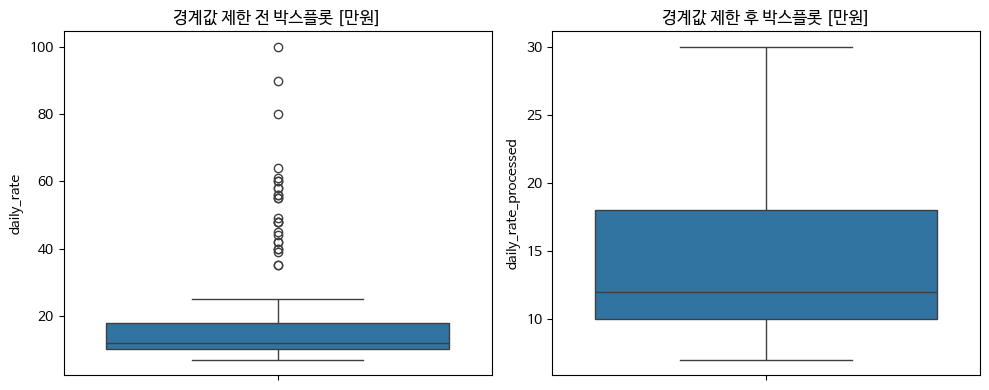

이상치 처리 방법 근거 Plot


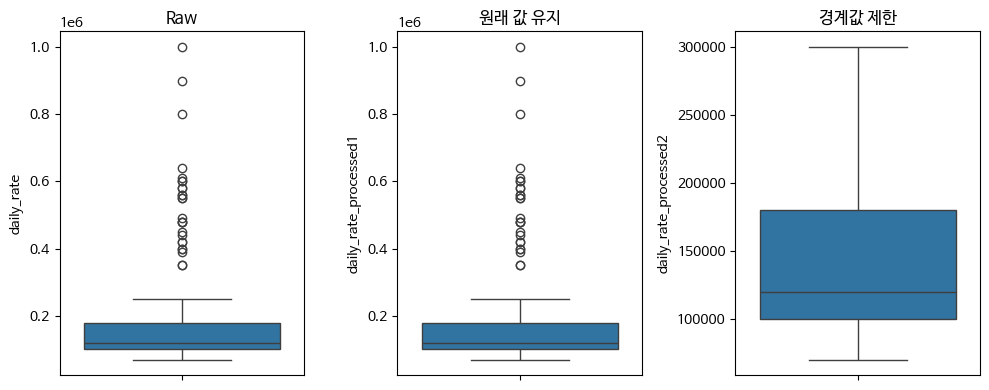

In [70]:
# 1. 문제 2에서 정제한 `booking_clean`을 사용합니다.
rate_s = booking_clean['daily_rate']

# 2. `daily_rate`의 제1사분위수(Q1), 제3사분위수(Q3), IQR을 계산합니다.
#     - `Q1, Q3 = quntile(0.25, 0.75)`
#     - `IQR = Q3 - Q1`
Q1_rate = rate_s.quantile(0.25)
Q3_rate = rate_s.quantile(0.75)
IQR_rate = Q3_rate - Q1_rate

print("daily_rate의 이상치 탐지:")
print(f"Q1 : {Q1_rate}")
print(f"Q3 : {Q3_rate}")
print(f"IQR : {IQR_rate}\n")

# 3. 아래 기준으로 하한과 상한을 계산합니다.
#     - `하한 = Q1 - 1.5 × IQR`
#     - `상한 = Q3 + 1.5 × IQR`
lower_bound_rate = Q1_rate - 1.5 * IQR_rate
upper_bound_rate = Q3_rate + 1.5 * IQR_rate

print(f"하한 값 : {lower_bound_rate}")
print(f"상한 값: {upper_bound_rate}\n")

# 4. 하한보다 작거나 상한보다 큰 값을 이상치 후보로 탐지합니다.
outliers = booking_clean[(rate_s < lower_bound_rate) | (rate_s > upper_bound_rate)].reset_index()

# 5. 이상치 후보의 건수와 비율(%)을 출력합니다.
print(f"이상치 후보의 건수 :{len(outliers)}")
print(f"이상치 후보의 비율(%) :{(len(outliers)/len(booking_clean) * 100):0.2f}\n")

# 6. 해당 예약의 `booking_id`, `room_type`, `daily_rate`를 출력합니다.
print("이상치 탐지된 예약 출력:")
print(outliers[['booking_id', 'room_type', 'daily_rate']],"\n")

# 7. 다음 중 하나를 선택하여 처리 결과를 `daily_rate_processed`라는 새 열에 저장합니다.
booking_clean['daily_rate_processed'] = booking_clean['daily_rate'].clip(lower=lower_bound_rate, upper=upper_bound_rate)

# 8. 원래 요금과 처리된 요금의 최솟값·중앙값·최댓값을 비교합니다.
rate_comp = booking_clean[['daily_rate', 'daily_rate_processed']].agg(['min', 'median', 'max'])

print("요금의 최솟값·중앙값·최댓값 비교:")
display(rate_comp)

# 9. 처리 전후 박스플롯을 작성하고 각각 제목을 붙입니다.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(y=(booking_clean['daily_rate']/10000), ax=axes[0])
axes[0].set_title('경계값 제한 전 박스플롯 [만원]')

sns.boxplot(y=(booking_clean['daily_rate_processed']/10000), ax=axes[1])
axes[1].set_title('경계값 제한 후 박스플롯 [만원]')

plt.tight_layout()
plt.show()


# [처리 방법 선택 이유] : 경계값 제한(clip) 선택
# - 이상치 후보 26건 중 25건이 Suite에 해당하며, 객실 유형에 따른 정상 고가 예약일 수 있어 행을 제외하면 유효한 예약 정보가 손실될 수 있습니다.
# - 최고 요금 1,000,000원은 평균과 시각화의 눈금에 큰 영향을 줄 수 있으므로, 비교용 daily_rate_processed에 경계값을 적용해 예약 건수를 유지했습니다.
# - IQR 범위 이탈은 분포상 검토 후보를 가리는 기준이므로, 입력 오류 여부는 객실 유형별 요금 정책이나 예약 원기록을 확인해야 판단할 수 있습니다.

# [근거] : 처리 전후 통계량 및 박스플롯 비교
# - 통계량 비교 결과, 최솟값(70,000원)과 중앙값(120,000원)은 동일하게 유지되고, 최댓값만 1,000,000원에서 상한값(300,000원)으로 조정
# - 박스플롯 비교에서도 '원래 값 유지'는 상단 극단값으로 인해 분포가 눌려 보이지만, '경계값 제한'은 기존 분포의 중심을 해치지 않으면서 이상치 왜곡을 효과적으로 줄여주는 것을 시각화
print("이상치 처리 방법 근거 Plot")
booking_clean['daily_rate_processed1'] = booking_clean['daily_rate']
booking_clean['daily_rate_processed2'] = booking_clean['daily_rate'].clip(lower=lower_bound_rate, upper=upper_bound_rate)

booking_clean[['daily_rate', 'daily_rate_processed1']].agg(['min', 'median', 'max'])
booking_clean[['daily_rate', 'daily_rate_processed2']].agg(['min', 'median', 'max'])

fig, axes = plt.subplots(1, 3, figsize=(10, 4))
sns.boxplot(y=booking_clean['daily_rate'], ax=axes[0])
axes[0].set_title('Raw')
sns.boxplot(y=booking_clean['daily_rate_processed1'], ax=axes[1])
axes[1].set_title('원래 값 유지')
sns.boxplot(y=booking_clean['daily_rate_processed2'], ax=axes[2])
axes[2].set_title('경계값 제한')
plt.tight_layout()
plt.show()

## 문제 4. 업무에 필요한 파생변수 생성
---

**과제 목표**

운영팀이 예약의 규모와 특성을 쉽게 파악할 수 있도록 파생변수를 생성하고, 분석 대상 예약을 정리합니다.

**수행 내용**

1. 아래 네 가지 파생변수를 생성합니다.

    **1.1**
    | 파생변수 | 생성 규칙 |
    | --- | --- |
    | total_nights | weekend_nights + weekday_nights |
    | total_guests | adults + children |
    | estimated_room_amount | daily_rate × total_nights |
    | lead_time_group | 아래 기준으로 예약 선행일수 구간 생성 |  
    
    **1.2**
    | lead_time 조건 | lead_time_group |
    | --- | --- |
    | 0일 이상 7일 이하 | Within7Days |
    | 7일 초과 30일 이하 | 8to30Days |
    | 30일 초과 | Over30Days |  
  
2. total_nights가 0이거나 	otal_guests가 0인 예약의 번호와 건수를 출력합니다.
3. 본 과제는 숙박과 투숙 인원이 있는 예약을 분석하므로, 위 예약은 제외합니다.
4. 최종 행 수와 주요 열의 처음 10개 행을 출력합니다.
5. lead_time이 7일일 때와 30일일 때 각각 올바른 구간에 포함되는지 확인합니다.

**필수 설명 및 참고**

- 네 파생변수를 운영팀이 어떻게 활용할 수 있는지 각각 한 문장으로 작성합니다.
- estimated_room_amount를 실제 매출이라고 부를 수 없는 이유를 작성합니다.
- 예상 객실 요금은 실제 예약에 기록된 유효 요금을 기준으로 계산하므로, **daily_rate_processed가 아닌 daily_rate를 사용합니다.**
- daily_rate_processed는 이상치 처리 전후의 차이를 비교하는 분석용 열입니다.
- 예상 객실 요금에는 실제 취소·환불·추가 요금 등이 반영되어 있지 않습니다.

**제출물**

- 네 파생변수 생성 코드와 결과
- 숙박일수 또는 투숙 인원이 0인 예약의 번호·건수와 제외 결과
- 최종 행 수와 주요 열의 처음 10개 행
- 선행일수 7일·30일 경계 검증 결과
- 각 파생변수 활용 설명 한 문장씩과 실제 매출이 아닌 이유

In [71]:
# 1. 아래 네 가지 파생변수를 생성합니다.
# (1) total_nights: 총 숙박일수 (주말 숙박일수 + 평일 숙박일수)
booking_clean['total_nights'] = booking_clean['weekend_nights'] + booking_clean['weekday_nights']

# (2) total_guests: 총 투숙 인원 (성인 + 어린이)
booking_clean['total_guests'] = booking_clean['adults'] + booking_clean['children']

# (3) estimated_room_amount: 예상 객실 요금 (1박당 요금 × 총 숙박일수)
booking_clean['estimated_room_amount'] = booking_clean['daily_rate'] * booking_clean['total_nights']

# (4) lead_time_group: 예약 선행일수 구간
    # - 0일 이상 7일 이하   -> 'Within7Days'
    # - 7일 초과 30일 이하  -> '8to30Days'
    # - 30일 초과          -> 'Over30Days'

bins = [-np.inf, 7, 30, np.inf]  # 경계값: (최소, 7], (7, 30], (30, 최대]
labels = ['Within7Days', '8to30Days', 'Over30Days']
booking_clean['lead_time_group'] = pd.cut(booking_clean['lead_time'], bins=bins, labels=labels)

# display(booking_clean['lead_time_group'])

# 2. total_nights가 0이거나 total_guests가 0인 예약의 번호와 건수를 출력합니다.
invalid_bookings = booking_clean[(booking_clean['total_nights'] == 0) | (booking_clean['total_guests'] == 0)]

print(f"숙박일수 또는 투숙인원이 0인 예약 번호:\n{invalid_bookings['booking_id'].tolist()}")
print(f"해당 예약 건수: {len(invalid_bookings)}건\n")

# 3. 본 과제는 숙박과 투숙 인원이 있는 예약을 분석하므로, 위 예약은 제외합니다.
booking_clean = booking_clean[(booking_clean['total_nights'] > 0) & (booking_clean['total_guests'] > 0)].copy()

# 4. 최종 행 수와 주요 열의 처음 10개 행을 출력합니다.
print(f"최종 행 수: {len(booking_clean)}")
main_cols = ['booking_id', 'total_nights', 'total_guests', 'daily_rate', 'estimated_room_amount', 'lead_time', 'lead_time_group']
display(booking_clean[main_cols].head(10))

# 5. lead_time이 7일일 때와 30일일 때 각각 올바른 구간에 포함되는지 확인합니다.
print("lead_time이 7일인 예약의 구간:")
display(booking_clean[booking_clean['lead_time'] == 7][['booking_id', 'lead_time', 'lead_time_group']].head())

print("lead_time이 30일인 예약의 구간:")
display(booking_clean[booking_clean['lead_time'] == 30][['booking_id', 'lead_time', 'lead_time_group']].head())


# [필수 설명 및 참고]
#
# [네 파생변수의 운영팀 활용 방안]
# - total_nights: 단기·장기 투숙 고객 비중을 파악하여 객실 회전율 관리와 청소·하우스키핑 인력 배치 계획에 활용
# - total_guests: 예약별 총 투숙 인원을 기준으로 객실 비품·엑스트라 베드 준비와 조식·부대시설 수요 예측에 활용
# - estimated_room_amount: 예약 건별 예상 객실 매출 규모를 사전에 파악하여 고액 예약 건 집중 관리 및 취소 리스크 대응 우선순위 설정에 활용
# - lead_time_group: 임박 예약과 사전 장기 예약의 비중 및 취소율 차이를 분석하여 시기별 객실 요금 정책과 프로모션·사전 확인 시점을 결정하는 데 활용
#
# [estimated_room_amount를 실제 매출이라고 부를 수 없는 이유]
# - (1) 취소·노쇼 및 미확정 투숙: 이미 취소된 예약(is_canceled == 1)이 포함되어 있으며, 미취소 예약(is_canceled == 0)도 기준 시점에 취소되지 않았을 뿐 최종 투숙 완료를 의미하지 않아 실제 매출로 확정되지 않습니다.
# - (2) 환불 및 예약 변경 미반영: 실제 예약 취소, 투숙 일정 변경, 조기 퇴실 등에 따른 환불이나 위약금 정산 내역이 반영되어 있지 않습니다.
# - (3) 추가 요금 및 할인 미반영: 객실 기본 요금(daily_rate × total_nights)만 단순 계산한 값이므로 식음료(F&B), 룸서비스, 부대시설 이용료 등의 추가 요금과 쿠폰·프로모션 할인이 제외되어 있습니다.
#
# [참고: estimated_room_amount 산출 시 daily_rate 사용 기준]
# - daily_rate_processed는 이상치 처리 전후의 차이를 비교하는 분석용 열이므로, 예상 객실 요금은 실제 예약에 기록된 유효 요금인 daily_rate를 기준으로 계산합니다.


숙박일수 또는 투숙인원이 0인 예약 번호:
['HB0052', 'HB0054', 'HB0053', 'HB0051']
해당 예약 건수: 4건

최종 행 수: 281


,booking_id,total_nights,total_guests,daily_rate,estimated_room_amount,lead_time,lead_time_group
0,HB0204,7.0,3.0,180000.0,1260000.0,15.0,8to30Days
1,HB0267,4.0,2.0,130000.0,520000.0,7.0,Within7Days
2,HB0153,6.0,1.0,70000.0,420000.0,28.0,8to30Days
3,HB0010,5.0,4.0,130000.0,650000.0,30.0,8to30Days
4,HB0234,4.0,3.0,120000.0,480000.0,171.0,Over30Days
5,HB0227,5.0,4.0,100000.0,500000.0,143.0,Over30Days
6,HB0197,3.0,2.0,160000.0,480000.0,91.0,Over30Days
7,HB0110,3.0,1.0,550000.0,1650000.0,27.0,8to30Days
8,HB0006,4.0,2.0,450000.0,1800000.0,6.0,Within7Days
9,HB0176,2.0,3.0,80000.0,160000.0,127.0,Over30Days


lead_time이 7일인 예약의 구간:


,booking_id,lead_time,lead_time_group
1,HB0267,7.0,Within7Days
32,HB0034,7.0,Within7Days
42,HB0287,7.0,Within7Days
164,HB0029,7.0,Within7Days
190,HB0062,7.0,Within7Days


lead_time이 30일인 예약의 구간:


,booking_id,lead_time,lead_time_group
3,HB0010,30.0,8to30Days
45,HB0064,30.0,8to30Days
91,HB0102,30.0,8to30Days
121,HB0173,30.0,8to30Days
284,HB0192,30.0,8to30Days


## 문제 5. 사전 확인 대상 예약 추출
---

**과제 목표**

운영팀이 정한 업무 규칙을 모두 만족하는 예약을 추출하고, 사전 확인 대상의 규모와 예상 객실 요금을 파악합니다.

**수행 내용**

1. 다음 네 가지 조건을 **모두** 만족하는 예약을 추출하여 `selected`에 저장합니다.
    - 아직 취소되지 않은 예약
    - 예정 입실일보다 60일 이상 전에 접수된 예약
    - 총 숙박일수가 3일 이상인 예약
    - 예약 경로가 `Online` 또는 `Agency`인 예약
2. 다음 열을 출력합니다.

    ```python
    [
        "booking_id",
        "booking_channel",
        "lead_time",
        "total_nights",
        "total_guests",
        "estimated_room_amount"
    ]
    ```

3. 예상 객실 요금이 큰 순서대로 정렬하여 처음 10개 행을 출력합니다.
4. 사전 확인 대상 예약의 전체 건수와 예상 객실 요금 합계를 출력합니다.
5. 추출된 데이터가 네 가지 조건을 모두 만족하는지 코드로 확인합니다.

**참고 및 주요 포인트**

- 조건을 결합할 때는 각 조건을 괄호로 묶습니다.
- ‘모두 만족’에는 `&`를 사용합니다.
- 두 예약 경로 중 하나에 해당하는지 검사할 때는 `isin()`을 사용할 수 있습니다.
- 참고: `isin()`, `sort_values()`, `all()`
- 이 조건은 운영팀이 정한 업무 규칙입니다. 추출된 예약이 반드시 취소되거나, 모델이 취소 가능성을 예측했다는 의미는 아닙니다.

**제출물**

- 네 조건을 모두 적용한 `selected` 생성 코드
- 지정된 여섯 열과 예상 객실 요금 내림차순 상위 10개 행
- 사전 확인 대상 전체 건수와 예상 객실 요금 합계
- 네 조건을 모두 만족하는지 확인한 코드·결과

In [72]:
# 1. 다음 네 가지 조건을 **모두** 만족하는 예약을 추출하여 `selected`에 저장합니다.
    # - 아직 취소되지 않은 예약
    #   (is_canceled == 0)
    # - 예정 입실일보다 60일 이상 전에 접수된 예약
    #   (lead_time >= 60)
    # - 총 숙박일수가 3일 이상인 예약
    #   (total_nights >= 3)
    # - 예약 경로가 `Online` 또는 `Agency`인 예약
    #   (booking_channel.isin(['Online', 'Agency']))

cond_not_canceled = (booking_clean['is_canceled'] == 0)
cond_lead_time    = (booking_clean['lead_time'] >= 60)
cond_nights       = (booking_clean['total_nights'] >= 3)
cond_channel      = (booking_clean['booking_channel'].isin(['Online', 'Agency']))

selected = booking_clean[cond_not_canceled & cond_lead_time & cond_nights & cond_channel].copy()

# 2. 다음 열을 출력합니다.
    # "booking_id",
    # "booking_channel",
    # "lead_time",
    # "total_nights",
    # "total_guests",
    # "estimated_room_amount"

target_cols = ['booking_id', 'booking_channel', 'lead_time', 'total_nights', 'total_guests', 'estimated_room_amount']

# 3. 예상 객실 요금이 큰 순서대로 정렬하여 처음 10개 행을 출력합니다.
selected_sorted = selected.sort_values(by='estimated_room_amount', ascending=False)

print("사전 확인 대상 예약 상위 10개 행 (예상 객실 요금 기준 내림차순):")
display(selected_sorted[target_cols].head(10))

# 4. 사전 확인 대상 예약의 전체 건수와 예상 객실 요금 합계를 출력합니다.

print(f"사전 확인 대상 예약 전체 건수: {len(selected)}건")
print(f"예상 객실 요금 합계: {selected['estimated_room_amount'].sum():,.0f}원\n")

# 5. 추출된 데이터가 네 가지 조건을 모두 만족하는지 코드로 확인합니다.
check_cond1 = (selected['is_canceled'] == 0).all()
check_cond2 = (selected['lead_time'] >= 60).all()
check_cond3 = (selected['total_nights'] >= 3).all()
check_cond4 = (selected['booking_channel'].isin(['Online', 'Agency'])).all()

print("네 조건을 모두 만족하는지 확인한 코드·결과:")
print("- 조건 1 만족 여부 (모두 미취소):", check_cond1)
print("- 조건 2 만족 여부 (모두 lead_time >= 60):", check_cond2)
print("- 조건 3 만족 여부 (모두 total_nights >= 3):", check_cond3)
print("- 조건 4 만족 여부 (모두 Online 또는 Agency):", check_cond4)
print("- 모든 조건 일치 여부:", check_cond1 & check_cond2 & check_cond3 & check_cond4)


사전 확인 대상 예약 상위 10개 행 (예상 객실 요금 기준 내림차순):


,booking_id,booking_channel,lead_time,total_nights,total_guests,estimated_room_amount
198,HB0028,Online,154.0,4.0,2.0,1920000.0
149,HB0084,Online,157.0,6.0,3.0,1440000.0
50,HB0181,Agency,79.0,7.0,2.0,1260000.0
292,HB0122,Online,133.0,4.0,2.0,1000000.0
52,HB0240,Online,115.0,7.0,1.0,910000.0
78,HB0067,Online,60.0,5.0,2.0,900000.0
232,HB0292,Online,154.0,5.0,4.0,900000.0
93,HB0225,Agency,84.0,7.0,2.0,840000.0
41,HB0077,Agency,150.0,3.0,2.0,750000.0
140,HB0116,Online,92.0,4.0,2.0,720000.0


사전 확인 대상 예약 전체 건수: 35건
예상 객실 요금 합계: 21,510,000원

네 조건을 모두 만족하는지 확인한 코드·결과:
- 조건 1 만족 여부 (모두 미취소): True
- 조건 2 만족 여부 (모두 lead_time >= 60): True
- 조건 3 만족 여부 (모두 total_nights >= 3): True
- 조건 4 만족 여부 (모두 Online 또는 Agency): True
- 모든 조건 일치 여부: True


## 문제 6. 예약 현황과 취소 비율 시각화
---

**과제 목표**

운영팀이 예약 특성과 취소 현황을 이해할 수 있도록 분포와 집단별 관측 취소율을 시각화하고 해석합니다.

**수행 내용**

1. **문제 4까지 완료한 전체 정제 데이터인 `booking_clean`을 사용합니다. 문제 5의 `selected`만 사용하지 않습니다.**
2. 다음 세 가지 차트를 작성합니다.

    | 분석 목적 | 시각화할 내용 | 사용할 차트 |
    | --- | --- | --- |
    | 예약이 입실 며칠 전에 이루어지는지 파악 | `lead_time`의 분포 | 히스토그램 |
    | 예약 경로별 취소 현황 비교 | `booking_channel`별 취소율 | 막대그래프 |
    | 예약 선행일수 구간별 취소 현황 비교 | `lead_time_group`별 취소율 | 막대그래프 |  

3. Matplotlib과 Seaborn으로 **각각 한 개 이상**의 차트를 작성합니다.
4. 모든 차트에 제목, X축 이름, Y축 이름을 설정합니다.
5. 글자 크기와 그림 크기를 조정하여 읽기 쉽게 표현합니다.
6. 취소율 차트를 작성하기 전에 집단별 예약 건수·취소 건수·취소율을 표로 출력합니다.
7. 취소율 차트의 Y축은 0~100%로 설정하고, 막대에 취소율 숫자를 표시합니다.
8. 선행일수 구간은 `["Within7Days", "8to30Days", "Over30Days"]` 순서로 표시합니다.
9. 각 차트 아래에 해석 코멘트를 1~2문장씩 작성합니다.

**취소율 계산**

집단별 취소율 = 해당 집단의 취소 예약 건수 / 해당 집단의 전체 예약 건수 × 100

**필수 설명 및 주의사항**

- 어떤 구간에 예약이 많이 모여 있는지 설명합니다.
- 어떤 예약 경로나 선행일수 구간에서 취소율이 높게 나타나는지 실제 수치로 설명합니다.
- 예약 건수가 적은 집단의 취소율은 해석에 주의가 필요함을 고려합니다.
- 취소 건수와 취소 비율을 구분합니다.
- 미취소 예약 중에는 이후 취소될 예약이 있을 수 있습니다. 따라서 이번 취소율은 데이터 기준 시점의 관측 취소율입니다.
- “온라인 예약이 취소를 일으킨다”처럼 인과관계를 단정하지 않습니다.

**제출물**

- 집단별 예약 건수·취소 건수·취소율 표
- 선행일수 히스토그램, 예약 경로별 취소율 막대그래프, 선행일수 구간별 취소율 막대그래프
- Matplotlib·Seaborn을 각각 한 개 이상 활용한 코드와 차트
- 모든 차트의 제목·축 이름·가독성 설정, 취소율 차트의 Y축 0~100%·숫자 표시, 지정된 구간 순서
- 각 차트 아래 해석 코멘트 1~2문장씩

In [73]:
#   (집단 취소율(%) = 해당 집단의 취소 예약 건수 / 해당 집단의 전체 예약 건수 × 100)

# 1. 문제 4까지 완료한 전체 정제 데이터 `booking_clean`을 사용합니다. (문제 5의 `selected` 사용 안 함)
print(f"분석 대상 전체 정제 데이터 건수: {len(booking_clean)}건\n")

group_order = ["Within7Days", "8to30Days", "Over30Days"]

channel_order = ["Online", "Direct", "Agency", "Unknown"]

# 6. 취소율 차트를 작성하기 전에 집단별 예약 건수·취소 건수·취소율을 표로 출력합니다.
# 7. 취소율 차트의 Y축은 0~100%로 설정하고, 막대에 취소율 숫자를 표시합니다.
# 8. 선행일수 구간은 ["Within7Days", "8to30Days", "Over30Days"] 순서로 표시합니다.
channel_summary = (
    booking_clean.groupby("booking_channel", observed=False)["is_canceled"]
    .agg(예약건수="count", 취소건수="sum", 취소율="mean")
    .reindex(channel_order)
    .assign(
        취소율=lambda df: (df["취소율"] * 100).round(2),  # lambda: 앞 단계 결과 DataFrame(df)을 받아 취소율을 %(소수 2자리)로 변환
        전체취소비중=lambda df: (df["취소건수"] / df["취소건수"].sum() * 100).round(2),  # lambda: 전체 취소 건수 대비 각 경로 취소 건수 비중(%) 계산
    )
)
print("예약 경로(booking_channel)별 예약 건수 · 취소 건수 · 관측 취소율 · 전체 취소 비중:")
display(channel_summary)

lead_summary = (
    booking_clean.groupby("lead_time_group", observed=False)["is_canceled"]
    .agg(예약건수="count", 취소건수="sum", 취소율="mean")
    .reindex(group_order)
    .assign(취소율=lambda df: (df["취소율"] * 100).round(2))  # lambda: 앞 단계 결과 DataFrame(df)을 받아 취소율을 %(소수 2자리)로 변환
)
print("예약 선행일수 구간(lead_time_group)별 예약 건수 · 취소 건수 · 관측 취소율:")
display(lead_summary)

# [참고] 코드에 사용된 `lambda` (람다/익명 함수) 설명 및 사용 방법
# `lambda`란?
# - `def`로 이름을 붙이지 않고, 한 줄로 간단히 만들어 바로 넘기는 익명 함수입니다.
# (예) `lambda x: x * 100`  ==  `def func(x): return x * 100`


분석 대상 전체 정제 데이터 건수: 281건

예약 경로(booking_channel)별 예약 건수 · 취소 건수 · 관측 취소율 · 전체 취소 비중:


,예약건수,취소건수,취소율,전체취소비중
booking_channel,,,,
Online,141,42,29.79,64.62
Direct,83,13,15.66,20.00
Agency,53,9,16.98,13.85
Unknown,4,1,25.00,1.54


예약 선행일수 구간(lead_time_group)별 예약 건수 · 취소 건수 · 관측 취소율:


,예약건수,취소건수,취소율
lead_time_group,,,
Within7Days,69,12,17.39
8to30Days,100,13,13.00
Over30Days,112,40,35.71


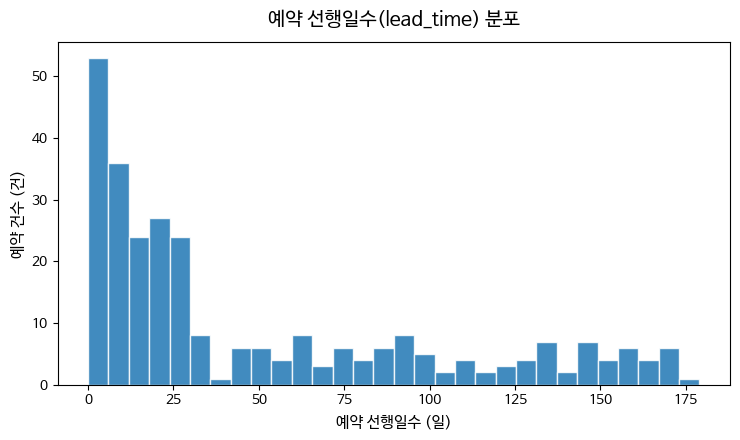

In [74]:
# 2. 다음 세 가지 차트를 작성합니다.
# 3. Matplotlib과 Seaborn으로 각각 한 개 이상의 차트를 작성합니다.
# 4. 모든 차트에 제목, X축 이름, Y축 이름을 설정합니다.
# 5. 글자 크기와 그림 크기를 조정하여 읽기 쉽게 표현합니다.

# 차트 1: `lead_time` 분포 히스토그램 (Matplotlib 활용)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.hist(booking_clean["lead_time"], bins=30, edgecolor="white", alpha=0.85)
ax.set_title("예약 선행일수(lead_time) 분포", fontsize=14, pad=12)
ax.set_xlabel("예약 선행일수 (일)", fontsize=11)
ax.set_ylabel("예약 건수 (건)", fontsize=11)
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()


**차트 1 해석**

- 전체 281건의 예약 중 입실 30일 이내(Within7Days 69건 + 8to30Days 100건 = 169건, 약 60.1%) 구간에 예약이 가장 많이 모여 있으며, 중앙값은 24일입니다.
- 반면 30일 이후에는 대체로 구간별 빈도가 낮아져 최대 179일까지 이어지는 오른쪽 꼬리가 긴 분포를 보입니다.


In [75]:
# 9. 각 차트 아래에 해석 코멘트를 1~2문장씩 작성합니다.
# [차트 1 근거]
total_n = len(booking_clean)
within_30_n = (booking_clean["lead_time"] <= 30).sum()
within_7_n = (booking_clean["lead_time"] <= 7).sum()
days_8to30_n = ((booking_clean["lead_time"] > 7) & (booking_clean["lead_time"] <= 30)).sum()

print("[차트 1 해석 근거 수치]")
print(f"- 전체 예약 건수: {total_n}건")
print(f"- 입실 30일 이내 예약: Within7Days {within_7_n}건 + 8to30Days {days_8to30_n}건 = {within_30_n}건 ({within_30_n / total_n * 100:.1f}%)")
print(f"- lead_time 최솟값: {booking_clean['lead_time'].min():.0f}일, 중앙값: {booking_clean['lead_time'].median():.0f}일, 최댓값: {booking_clean['lead_time'].max():.0f}일\n")




[차트 1 해석 근거 수치]
- 전체 예약 건수: 281건
- 입실 30일 이내 예약: Within7Days 69건 + 8to30Days 100건 = 169건 (60.1%)
- lead_time 최솟값: 0일, 중앙값: 24일, 최댓값: 179일



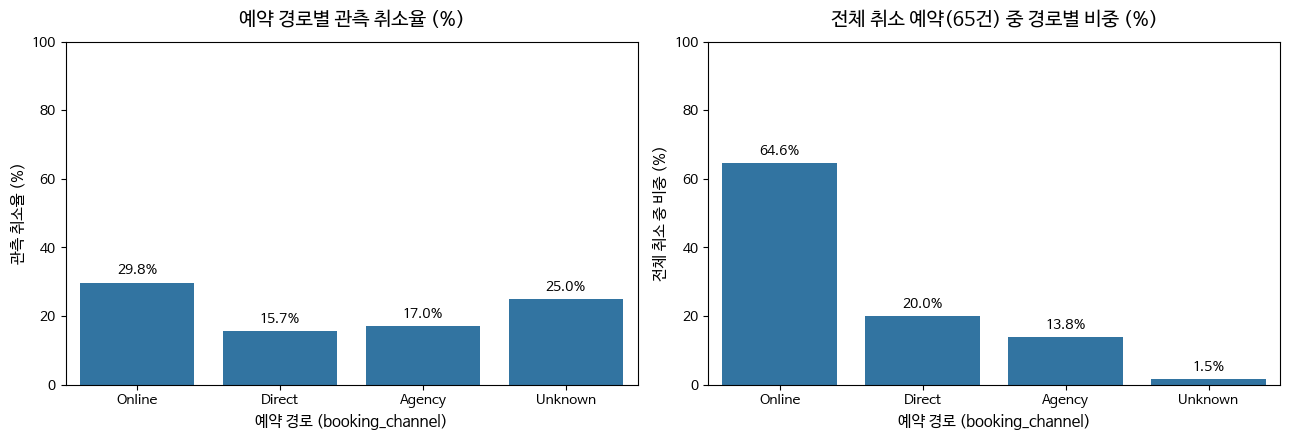

In [76]:
# 차트 2: `booking_channel`별 관측 취소율 및 전체 취소 중 경로별 비중 막대그래프 (Seaborn 활용, booking_clean 직접 집계)
canceled_only = booking_clean[booking_clean["is_canceled"] == 1]
cancel_share = (
    canceled_only["booking_channel"]
    .value_counts(normalize=True)
    .reindex(channel_order, fill_value=0)
    .mul(100)
    .reset_index(name="전체취소비중")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (좌) 예약 경로별 관측 취소율 (%)
sns.barplot(
    data=booking_clean,
    x="booking_channel",
    y="is_canceled",
    order=channel_order,
    estimator=lambda s: np.mean(s) * 100,  # lambda: 각 그룹의 is_canceled 배열 s를 받아 백분율(%)로 변환하는 익명 함수
    errorbar=None,
    ax=axes[0],
)
axes[0].set_ylim(0, 100)
axes[0].set_title("예약 경로별 관측 취소율 (%)", fontsize=14, pad=12)
axes[0].set_xlabel("예약 경로 (booking_channel)", fontsize=11)
axes[0].set_ylabel("관측 취소율 (%)", fontsize=11)
axes[0].tick_params(labelsize=10)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontsize=10)

# (우) 전체 취소 예약 중 경로별 차지 비중 (%)
sns.barplot(
    data=cancel_share,
    x="booking_channel",
    y="전체취소비중",
    order=channel_order,
    ax=axes[1],
)
axes[1].set_ylim(0, 100)
axes[1].set_title(f"전체 취소 예약({len(canceled_only)}건) 중 경로별 비중 (%)", fontsize=14, pad=12)
axes[1].set_xlabel("예약 경로 (booking_channel)", fontsize=11)
axes[1].set_ylabel("전체 취소 중 비중 (%)", fontsize=11)
axes[1].tick_params(labelsize=10)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=3, fontsize=10)

plt.tight_layout()
plt.show()


**차트 2 해석**

- Online 경로는 141건 중 42건이 취소되어 관측 취소율(29.79%)이 주요 경로 중 가장 높을 뿐만 아니라, 전체 취소 예약 65건 중 64.62%(42건)를 차지해 취소 규모와 비율 모두 가장 큽니다.
- 반면 Unknown 경로는 관측 취소율이 25.00%로 높아 보이지만 전체 예약이 4건(취소 1건)으로 전체 취소 중 비중이 1.54%에 불과해 소표본 해석에 주의해야 하며, 이는 기준 시점의 관측 취소율일 뿐 특정 경로가 취소를 유발한다고 단정할 수 없습니다.


In [77]:
# [차트 2 근거]
print("[차트 2 해석 근거 수치]")
total_canceled_n = int(channel_summary["취소건수"].sum())
print(f"- 전체 취소 예약 건수: {total_canceled_n}건 (정제 데이터 {total_n}건 중 {total_canceled_n / total_n * 100:.2f}%)")
for ch, row in channel_summary.iterrows():
    print(
        f"- {ch}: 전체 {int(row['예약건수'])}건 중 취소 {int(row['취소건수'])}건 "
        f"(관측 취소율 {row['취소율']:.2f}%, 전체 취소 중 비중 {row['전체취소비중']:.2f}%)"
    )
print()




[차트 2 해석 근거 수치]
- 전체 취소 예약 건수: 65건 (정제 데이터 281건 중 23.13%)
- Online: 전체 141건 중 취소 42건 (관측 취소율 29.79%, 전체 취소 중 비중 64.62%)
- Direct: 전체 83건 중 취소 13건 (관측 취소율 15.66%, 전체 취소 중 비중 20.00%)
- Agency: 전체 53건 중 취소 9건 (관측 취소율 16.98%, 전체 취소 중 비중 13.85%)
- Unknown: 전체 4건 중 취소 1건 (관측 취소율 25.00%, 전체 취소 중 비중 1.54%)



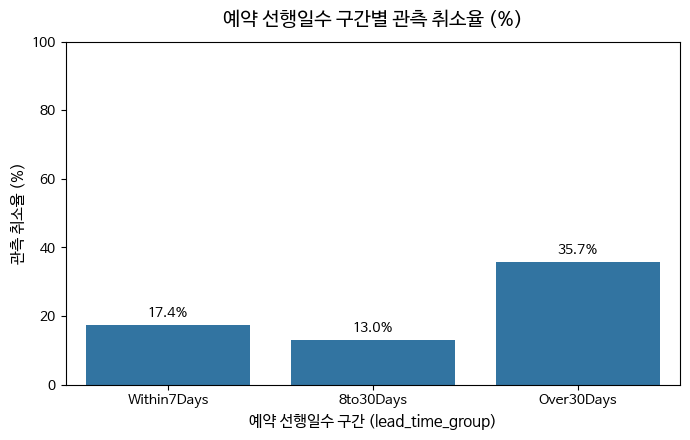

In [78]:
# 차트 3: `lead_time_group`별 취소율 막대그래프 (Seaborn 활용, booking_clean 직접 집계)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(
    data=booking_clean,
    x="lead_time_group",
    y="is_canceled",
    order=group_order,
    estimator=lambda s: np.mean(s) * 100,  # lambda: 각 구간 그룹의 is_canceled 배열 s를 받아 백분율(%)로 변환
    errorbar=None,
    ax=ax,
)
ax.set_ylim(0, 100)
ax.set_title("예약 선행일수 구간별 관측 취소율 (%)", fontsize=14, pad=12)
ax.set_xlabel("예약 선행일수 구간 (lead_time_group)", fontsize=11)
ax.set_ylabel("관측 취소율 (%)", fontsize=11)
ax.tick_params(labelsize=10)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=10)
plt.tight_layout()
plt.show()


**차트 3 해석**

- Over30Days 구간은 112건 중 40건이 취소되어 관측 취소율이 35.71%로, Within7Days(69건 중 12건, 17.39%) 및 8to30Days(100건 중 13건, 13.00%)에 비해 두 배 이상 높습니다.
- 현재 미취소 예약 중에도 입실 전 추가 취소가 발생할 수 있으므로 위 수치는 데이터 기준 시점의 관측 취소율이며, 선행일수와 취소 간의 인과관계로 단정하지 않고 사전 확인 대상으로 관리하는 데 활용해야 합니다.


In [79]:
# [차트 3 근거]
print("[차트 3 해석 근거 수치]")
for grp, row in lead_summary.iterrows():
    print(f"- {grp}: 전체 {int(row['예약건수'])}건 중 취소 {int(row['취소건수'])}건 (관측 취소율 {row['취소율']:.2f}%)")
over30_rate = lead_summary.loc["Over30Days", "취소율"]
within7_rate = lead_summary.loc["Within7Days", "취소율"]
days8to30_rate = lead_summary.loc["8to30Days", "취소율"]
print(f"- Over30Days 대비 배수: Within7Days의 {over30_rate / within7_rate:.2f}배, 8to30Days의 {over30_rate / days8to30_rate:.2f}배")


[차트 3 해석 근거 수치]
- Within7Days: 전체 69건 중 취소 12건 (관측 취소율 17.39%)
- 8to30Days: 전체 100건 중 취소 13건 (관측 취소율 13.00%)
- Over30Days: 전체 112건 중 취소 40건 (관측 취소율 35.71%)
- Over30Days 대비 배수: Within7Days의 2.05배, 8to30Days의 2.75배


## 문제 7. 예약 운영팀에 분석 결과 전달
---

**과제 목표**

분석에서 확인한 사실과 제안을 구분하여 운영팀에 전달할 수 있는 결과 요약을 작성합니다.

**수행 내용**

분석 결과를 바탕으로 아래 내용을 **5~7문장**으로 정리합니다.

1. 주요 데이터 품질 문제와 처리 방법
2. 차트에서 확인한 예약·취소 특성
3. 사전 확인 대상 예약의 건수와 특징
4. 운영팀이 추가로 검토하면 좋을 사항 한 가지
5. 분석의 한계 또는 추가로 필요한 데이터 한 가지

**주요 포인트**

- 본인의 실행 결과에 근거하여 작성합니다.
- 가상 데이터에서 관찰한 결과를 실제 호텔 전체의 특성으로 일반화하지 않습니다.
- 데이터에서 확인한 사실과 본인이 제안하는 의견을 구분합니다.

**제출물**

- 위 다섯 항목을 포함한 5~7문장의 분석 결과 요약

In [80]:
# 작성 기준:
# - 아래 5가지 필수 항목을 포함하여 총 5~7문장(현재 6문장)으로 정리합니다.
#   1. 주요 데이터 품질 문제와 처리 방법
#   2. 차트에서 확인한 예약·취소 특성
#   3. 사전 확인 대상 예약의 건수와 특징
#   4. 운영팀이 추가로 검토하면 좋을 사항 한 가지
#   5. 분석의 한계 또는 추가로 필요한 데이터 한 가지

# 주요 포인트:
# - 본인의 실행 결과에 근거하여 작성합니다.
# - 가상 데이터에서 관찰한 결과를 실제 호텔 전체의 특성으로 일반화하지 않습니다.
# - 데이터에서 확인한 사실과 본인이 제안하는 의견을 구분합니다.

<!-- 해당 칸에 요약 작성 -->
### 문제 7 : 예약 운영팀 분석 결과 요약 전달

**분석 결과**  
원본 300건 중 필수 일수·인원 열에 오류 또는 결측이 있는 15건을 제외하고, 요금 오류·결측 6건은 유효 요금의 중앙값인 120,000원으로, 객실 유형과 예약 경로의 결측은 ‘Unknown’으로 대체했습니다.
총 숙박일수 또는 총 투숙 인원이 0인 4건을 추가로 제외한 결과, 최종 281건 중 169건(60.1%)이 입실 30일 이내에 접수됐습니다.
관측 취소율은 예약 경로 중 Online(29.79%), 선행일수 구간 중 30일 초과(35.71%)에서 각각 가장 높았습니다.
선행일수 60일 이상, 3박 이상, Online·Agency 경로의 미취소 예약 35건이 사전 확인 대상이며, 예상 객실 요금 합계는 21,510,000원입니다.

**운영 제안**  
사전 확인 대상 35건에 입실 1~2주 전 예약 유지 여부를 확인하는 방안을 제안합니다.

**분석 한계**  
교육용 데이터의 취소율은 기준 시점의 관측치이므로, 최종 취소율을 산출하려면 각 예약의 입실 예정일 이후 최종 상태가 필요합니다.


### 참고 자료

[호텔 예약 데이터 분석 결과 보고]

#### 1. 데이터 품질 및 정제:
원본 300건 중 필수 일수·인원 열에 음수 또는 결측이 있는 예약 15건을 제외했습니다. 음수·0원 요금과 요금 결측이 있던 6건은 유효 요금의 중앙값인 120,000원으로 대체했습니다.
총 숙박일수 또는 총 투숙 인원이 0인 예약 4건을 추가로 제외해 최종 분석 대상은 281건입니다.

    - 유효성(Validity)    : 음수 일수·인원, 0원 이하 요금, 숙박/인원 0건 등 업무 규칙에 어긋나는 비유효 값 제거
    - 완전성(Completeness): 결측치(NaN) 행 제외 및 범주형 결측 처리로 남은 결측치 0건 상태 확보
    - 무결성(Integrity)   : 원본에서 예약 번호 중복이 없음을 확인하고, 정제 후 음수 일수·인원과 0원 이하 요금이 남아 있는지 검증

객실 요금(daily_rate) 이상치 후보 26건(9.12%)은 비교 분석용 열(daily_rate_processed)에 IQR 상한(300,000원) 경계값 제한을 적용하되,
실제 요금 계산에는 유효 요금(daily_rate)과 통일된 파생변수·구간 규칙을 적용해 분석의 정확성·일관성·정합성을 유지

    - 정확성(Accuracy)    : 오류 값 제거 및 실제 유효 요금(daily_rate) 기준 산출로 왜곡 없는 수치 계산
    - 일관성(Consistency) : 파생변수 공식과 lead_time_group 경계 기준(7일·30일)을 전체 데이터에 동일하게 적용
    - 정합성(Coherence)   : 정제 데이터·파생변수·추출 조건(.all() 검증) 간 상호 모순이 없도록 교차 확인

#### 2. 예약 및 취소 특성 (사실):
정제된 데이터 281건의 분포를 확인한 결과, 예약은 입실 30일 이내(169건, 60.1%, 중앙값 24일)에 집중되어 있으며 기준 시점의 관측 취소율 및 전체 취소 비중은 다음과 같이 확인

    - 전체 정제 데이터: 281건 (전체 취소 65건, 전체 관측 취소율 23.13%)
      · 예약 분포: 입실 30일 이내 169건(60.1%, 중앙값 24일) 집중, 30일 초과 112건(39.9%, 최대 179일)

    - 예약 경로별 관측 취소율 및 전체 취소 비중: Online 경로가 관측 취소율(29.79%)과 전체 취소 비중(64.62%, 42건) 모두 가장 높음
      · Online : 141건 중 42건 취소 (관측 취소율 29.79%, 전체 취소 중 64.62%)
      · Direct :  83건 중 13건 취소 (관측 취소율 15.66%, 전체 취소 중 20.00%)
      · Agency :  53건 중  9건 취소 (관측 취소율 16.98%, 전체 취소 중 13.85%)
      · Unknown:   4건 중  1건 취소 (관측 취소율 25.00%, 전체 취소 중  1.54% — 소표본 해석 주의 필요)

    - 선행일수 구간별 관측 취소율 및 전체 취소 비중: Over30Days 구간이 관측 취소율(35.71%)과 전체 취소 비중(61.54%, 40건) 모두 가장 높음
      · Within7Days:  69건 중 12건 취소 (관측 취소율 17.39%, 전체 취소 중 18.46%)
      · 8to30Days  : 100건 중 13건 취소 (관측 취소율 13.00%, 전체 취소 중 20.00%)
      · Over30Days : 112건 중 40건 취소 (관측 취소율 35.71%, 전체 취소 중 61.54%)

#### 3. 사전 확인 대상 예약 현황 (사실):
운영 조건(미취소, 선행일수 60일 이상, 3박 이상, Online·Agency 경로)의 정합성을 검증해 추출한 사전 확인 대상 예약은 총 35건,
예상 객실 요금 합계는 21,510,000원이며 최고액은 1,920,000원입니다.

#### 4. 운영팀 검토 제안 (제안):
위 관찰 사실을 바탕으로, 운영팀에서는 전체 취소의 64.62%를 차지하는 Online 경로와 사전 확인 대상 35건을 우선순위로 두고 다음을 제안

    1. 입실 1~2주 전 리컨펌(알림톡 발송·유선 확인)
    2. 보증금·취소 규정 안내를 강화하는 방안을 검토

#### 5. 분석의 한계 및 추가 필요 데이터:
본 결과는 가상 데이터의 특정 기준 시점에서 확인된 관측치이므로 실제 호텔 전체 특성으로 일반화하거나 경로·선행일수와 취소 간의 인과관계로 단정할 수 없으며,
예상 객실 요금에 미반영된 취소·환불·부가서비스 내역과 실제 최종 결제·취소 사유 데이터가 추가 확보된다면 분석의 정확성과 정합성을 더욱 높일 수 있을 것으로 판단

## 최종 제출물
---

문제번호 별 코드·실행 결과·설명을 포함한 **주피터 노트북(`.ipynb`)** 을 GitHub에 업로드하고, 개인 GitHub 저장소 URL을 제출합니다.

- 문제 1: 데이터 구조·예약 현황·결측치 표와 정제 필요 항목 두 가지 이상
- 문제 2: 오류 탐지·셀 단위 결측 처리·결측치 처리, 전후 행 수·제외 행 수·남은 결측치·오류 잔존 검증 및 처리 근거
- 문제 3: Q1·Q3·IQR·하한·상한, 이상치 후보 목록·건수·비율, `daily_rate_processed`, 전후 통계·박스플롯, 처리 근거 2~3문장과 오류 판정 설명
- 문제 4: 네 파생변수, 숙박일수·인원이 0인 예약의 번호·건수와 제외 결과, 최종 행 수·처음 10개 행, 7일·30일 경계 검증, 활용 설명·매출 해석의 한계
- 문제 5: 네 조건을 모두 만족하는 `selected`, 지정 열의 예상 객실 요금 내림차순 상위 10개 행, 전체 건수·예상 객실 요금 합계, 조건 검증
- 문제 6: 전체 `booking_clean` 기반 집단별 예약·취소 건수·취소율 표, 세 가지 차트, 각 차트 아래 1~2문장의 해석
- 문제 7: 필수 다섯 항목이 포함된 5~7문장의 운영팀 전달 요약